# 🟢 Step 2 — Libraries aur Project Setup

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Project folder:", Path.cwd())

OpenCV version: 5.0.0
NumPy version: 2.5.1
Project folder: D:\shayan ai agent course\computer vision\05_Face_Detection_Project


# 🟢 Step 3 — Face Detection Model Ready Karna

In [2]:
from pathlib import Path

model_path = Path("face_detection_yunet_2026may.onnx")

print("Model exists:", model_path.exists())
print("Model path:", model_path)

Model exists: True
Model path: face_detection_yunet_2026may.onnx


#     🟢 Step 4 — YuNet Model Load Karna

In [4]:
face_detector = cv2.FaceDetectorYN.create(
    str(model_path),
    "",
    (320, 320),
    0.6,
    0.3,
    5000
)

print("YuNet face detector loaded successfully.")

YuNet face detector loaded successfully.


# 🟢 Step 5 — Input Image Load Karna

In [7]:
image_path = Path("ayanfriendpic.jpeg")

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

print("Image loaded successfully.")
print("Image shape:", image.shape)

Image loaded successfully.
Image shape: (4032, 3024, 3)


# 🟢 Step 6 — YuNet se Faces Detect Karna

In [8]:
height, width = image.shape[:2]

face_detector.setInputSize((width, height))

_, faces = face_detector.detect(image)

print("Faces detected:", 0 if faces is None else len(faces))

Faces detected: 9


# 🟢 Step 7 — Bounding Boxes Draw Karna

In [9]:
output_image = image.copy()

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)

        cv2.rectangle(
            output_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

print("Bounding boxes drawn successfully.")

Bounding boxes drawn successfully.


# 🟢 Step 8 — Detection Result Display Karna

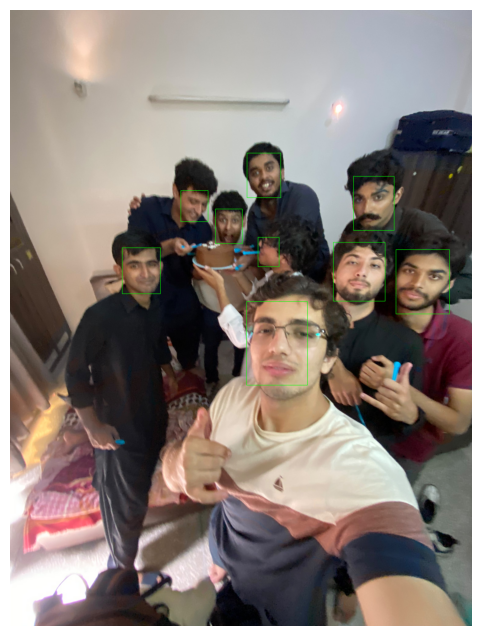

In [10]:
image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

# 🟢 Step 9 — Face Count Display Karna

In [11]:
face_count = 0 if faces is None else len(faces)

cv2.putText(
    output_image,
    f"Faces Detected: {face_count}",
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 255, 0),
    2
)

print(f"Faces detected: {face_count}")

Faces detected: 9


#     Step 10 — Face Confidence Score

In [12]:
output_image = image.copy()

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        confidence = face[-1]

        cv2.rectangle(
            output_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            output_image,
            f"Face: {confidence:.2f}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

print("Confidence scores added successfully.")

Confidence scores added successfully.


# Step 11 — Facial Landmarks

In [14]:
output_image = image.copy()

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        confidence = face[-1]

        cv2.rectangle(
            output_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            output_image,
            f"Face: {confidence:.2f}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        landmarks = face[4:14].reshape(5, 2).astype(int)

        for point_x, point_y in landmarks:
            cv2.circle(
                output_image,
                (point_x, point_y),
                4,
                (255, 0, 0),
                -1
            )

print("Facial landmarks added successfully.")

Facial landmarks added successfully.


# Step 12 — Combined Professional Output

In [18]:
output_image = image.copy()

face_count = 0 if faces is None else len(faces)

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        confidence = face[-1]

        # Bounding box
        cv2.rectangle(
            output_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        # Confidence
        cv2.putText(
            output_image,
            f"Face: {confidence:.2f}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        # Facial landmarks
        landmarks = face[4:14].reshape(5, 2).astype(int)

        for point_x, point_y in landmarks:
            cv2.circle(
                output_image,
                (point_x, point_y),
                4,
                (255, 0, 0),
                -1
            )

# Face count
    cv2.putText(
        output_image,
        f"Faces Detected: {face_count}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )
    
    print(f"Faces detected: {face_count}")

Faces detected: 9


# Step 13 — Display Final Detection

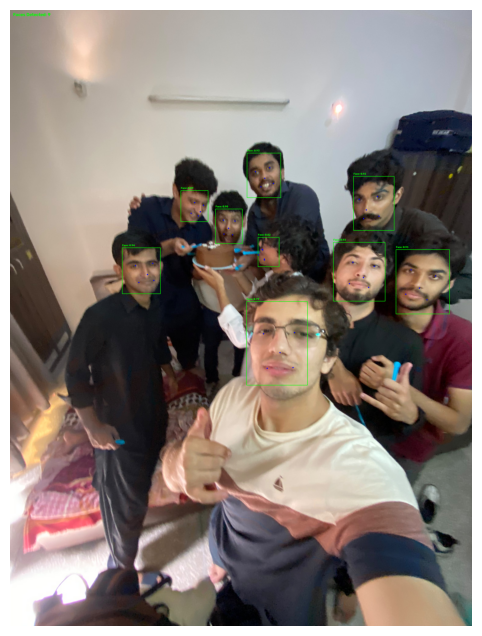

In [19]:
image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

# Step 14 — Confidence Threshold Filtering.

In [20]:
confidence_threshold = 0.60

filtered_faces = []

if faces is not None:
    for face in faces:
        confidence = face[-1]

        if confidence >= confidence_threshold:
            filtered_faces.append(face)

print(f"Original detections: {0 if faces is None else len(faces)}")
print(f"Accepted detections: {len(filtered_faces)}")

Original detections: 9
Accepted detections: 9


# mStep 15 — Filtered Faces Draw Karna

In [23]:
output_image = image.copy()

for face in filtered_faces:
    x, y, w, h = face[:4].astype(int)
    confidence = face[-1]

    cv2.rectangle(
        output_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output_image,
        f"Face: {confidence:.2f}",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

    landmarks = face[4:14].reshape(5, 2).astype(int)

    for point_x, point_y in landmarks:
        cv2.circle(
            output_image,
            (point_x, point_y),
            4,
            (255, 0, 0),
            -1
        )

cv2.putText(
    output_image,
    f"Faces Detected: {len(filtered_faces)}",
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 255, 0),
    2
)

print("Filtered detection output created successfully.")

Filtered detection output created successfully.


# filter display

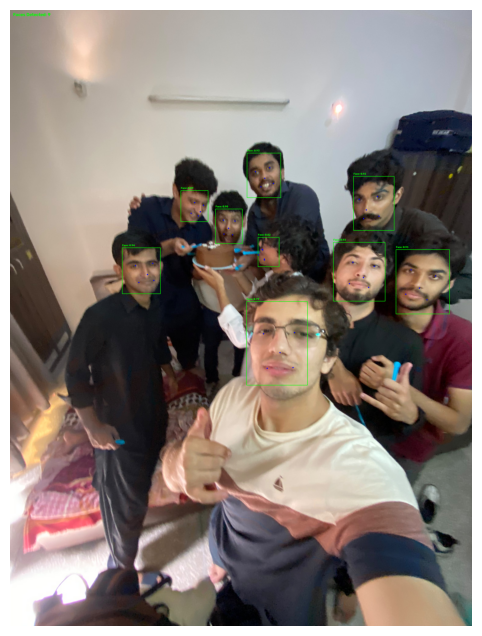

In [24]:
image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

# Step 17 — Reusable Function

In [25]:
def detect_faces(image, detector, confidence_threshold=0.60):
    height, width = image.shape[:2]
    detector.setInputSize((width, height))

    _, faces = detector.detect(image)

    if faces is None:
        return []

    return [
        face
        for face in faces
        if face[-1] >= confidence_threshold
    ]

# Step 18 — Function Call

In [27]:
filtered_faces = detect_faces(
    image,
    face_detector,
    confidence_threshold=0.60
)

print(f"Accepted faces: {len(filtered_faces)}")

Accepted faces: 9


# Step 19 — Detection Function ko Test Karna

In [29]:
for threshold in [0.50, 0.60, 0.80]:
    detected_faces = detect_faces(
        image,
        face_detector,
        confidence_threshold=threshold
    )

    print(f"Threshold {threshold:.2f} → {len(detected_faces)} faces")

Threshold 0.50 → 9 faces
Threshold 0.60 → 9 faces
Threshold 0.80 → 8 faces


# Ab Step 21 — Annotated Image Save karte hain.

In [30]:
output_path = Path("face_detection_result.jpg")

success = cv2.imwrite(
    str(output_path),
    output_image
)

if not success:
    raise RuntimeError("Failed to save the output image.")

print(f"Result saved successfully: {output_path}")

Result saved successfully: face_detection_result.jpg


# Step 22 — Image Validation

In [31]:
image_path = Path("ayanfriendpic.jpeg")

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(
        f"Unable to load image: {image_path}"
    )

if image.ndim != 3 or image.shape[2] != 3:
    raise ValueError(
        "Expected a 3-channel color image."
    )

print("Input image validated successfully.")
print("Image shape:", image.shape)

Input image validated successfully.
Image shape: (4032, 3024, 3)


# Step 23 — Detection Pipeline Function

In [32]:
def run_face_detection(
    image,
    detector,
    confidence_threshold=0.60
):
    if image is None:
        raise ValueError("Input image is empty.")

    height, width = image.shape[:2]
    detector.setInputSize((width, height))

    _, faces = detector.detect(image)

    if faces is None:
        return []

    filtered_faces = [
        face
        for face in faces
        if face[-1] >= confidence_threshold
    ]

    return filtered_faces

# Step 24 — Run the Detection Pipeline

In [33]:
detected_faces = run_face_detection(
    image,
    face_detector,
    confidence_threshold=0.60
)

print(f"Accepted faces: {len(detected_faces)}")

Accepted faces: 9


# Step 25 — Visualization Function

In [34]:
def draw_face_results(image, faces):
    output = image.copy()

    for face in faces:
        x, y, w, h = face[:4].astype(int)
        confidence = face[-1]

        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            output,
            f"Face: {confidence:.2f}",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        landmarks = face[4:14].reshape(5, 2).astype(int)

        for point_x, point_y in landmarks:
            cv2.circle(
                output,
                (point_x, point_y),
                4,
                (255, 0, 0),
                -1
            )

    cv2.putText(
        output,
        f"Faces Detected: {len(faces)}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )

    return output

# Step 26 — Generate Final Annotated Image

In [35]:
output_image = draw_face_results(
    image,
    detected_faces
)

print("Face visualization generated successfully.")

Face visualization generated successfully.


# Step 27 — Display Final Project Result

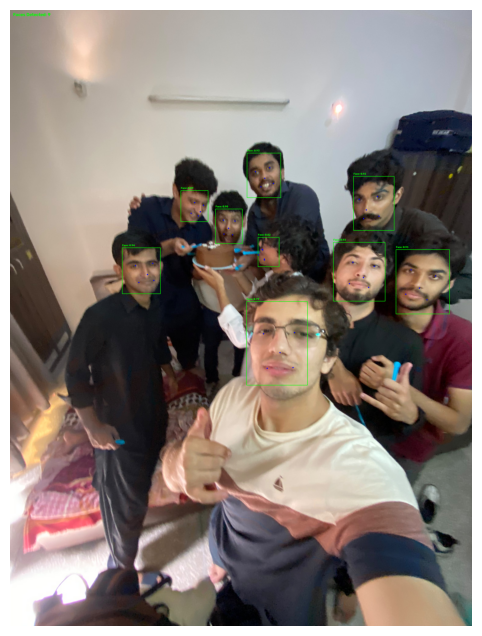

In [37]:
image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

# Step 28 — Measure Detection Time

In [40]:
import time

start_time = time.perf_counter()

detected_faces = run_face_detection(
    image,
    face_detector,
    confidence_threshold=0.60
)

end_time = time.perf_counter()

processing_time = end_time - start_time

print(f"Processing time: {processing_time:.4f} seconds")

Processing time: 1.8088 seconds


# Step 29 — FPS Calculate Karna# 

In [41]:
fps = 1 / processing_time

print(f"Estimated FPS: {fps:.2f}")

Estimated FPS: 0.55


# save imgae ko check

In [42]:
output_path = Path("face_detection_result.jpg")

print("File exists:", output_path.exists())
print("File path:", output_path.resolve())

File exists: True
File path: D:\shayan ai agent course\computer vision\05_Face_Detection_Project\face_detection_result.jpg


# Step 31 — Project Result ko Function se Save Karna

In [43]:
def save_result(image, output_path):
    output_path = Path(output_path)

    success = cv2.imwrite(
        str(output_path),
        image
    )

    if not success:
        raise RuntimeError(
            f"Failed to save image: {output_path}"
        )

    return output_path

# Ab naye function ko actually chalana hai

In [44]:
saved_path = save_result(
    output_image,
    "face_detection_result.jpg"
)

print(f"Result saved to: {saved_path.resolve()}")

Result saved to: D:\shayan ai agent course\computer vision\05_Face_Detection_Project\face_detection_result.jpg


#  ❤️ Step 33 — Final Clean Pipeline start karte hain.

# Step 33 — Pipeline Function

In [45]:
def process_face_detection(
    image,
    detector,
    confidence_threshold=0.60
):
    detected_faces = run_face_detection(
        image,
        detector,
        confidence_threshold
    )

    output_image = draw_face_results(
        image,
        detected_faces
    )

    return output_image, detected_faces

# Step 34 — Run Final Pipeline

In [46]:
final_image, detected_faces = process_face_detection(
    image,
    face_detector,
    confidence_threshold=0.60
)

print(f"Faces detected: {len(detected_faces)}")
print("Final pipeline executed successfully.")

Faces detected: 9
Final pipeline executed successfully.


# Step 35 — Display Final Pipeline Result

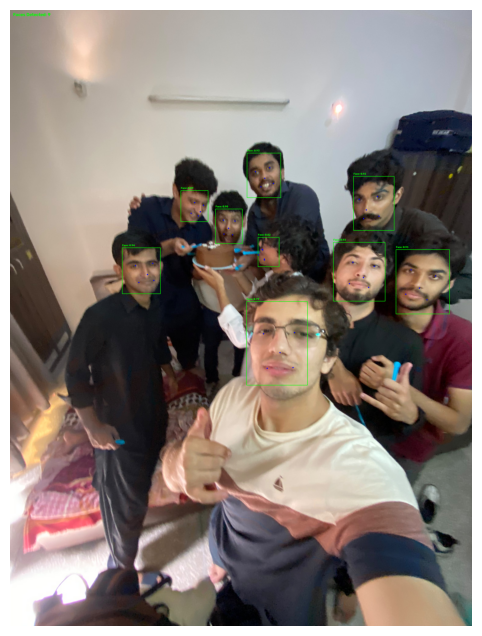

In [48]:
final_image_rgb = cv2.cvtColor(
    final_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 8))
plt.imshow(final_image_rgb)
plt.axis("off")
plt.show()

# Step 36 — Live Webcam Face Detection 🎥

# Step 36 — Webcam Open Karna

In [55]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Unable to open webcam.")

print("Webcam opened successfully.")

Webcam opened successfully.


# Step 37 — Read One Webcam Frame

In [56]:
ret, frame = cap.read()

if not ret:
    raise RuntimeError("Failed to read frame from webcam.")

print("Frame captured successfully.")
print("Frame shape:", frame.shape)

Frame captured successfully.
Frame shape: (480, 640, 3)


# Step 38 — Webcam frame par face detection

In [57]:
detected_faces = run_face_detection(
    frame,
    face_detector,
    confidence_threshold=0.60
)

print(f"Faces detected: {len(detected_faces)}")

Faces detected: 1


# Step 39 — Detected faces ko webcam frame par draw karna

In [58]:
annotated_frame = draw_face_results(
    frame,
    detected_faces
)

print("Face detection results drawn successfully.")

Face detection results drawn successfully.


# Step 40 — Annotated frame display karna

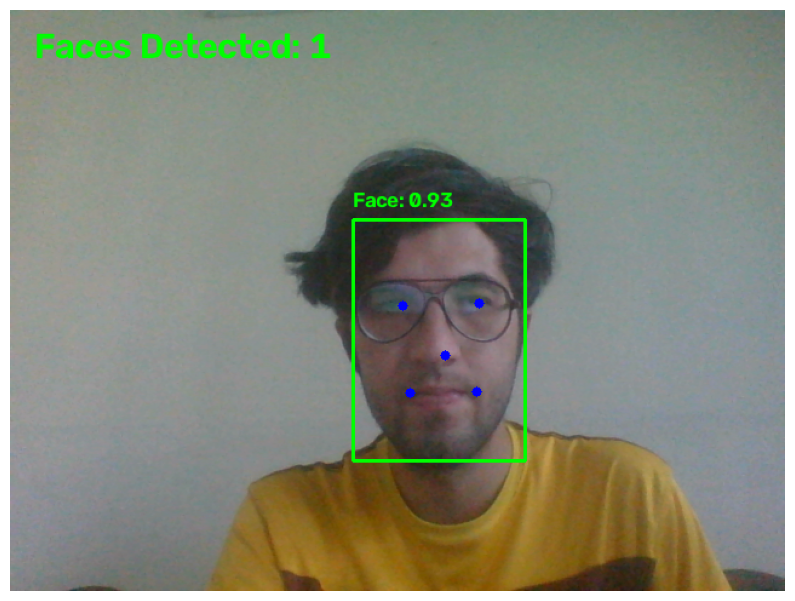

In [59]:
annotated_rgb = cv2.cvtColor(
    annotated_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 8))
plt.imshow(annotated_rgb)
plt.axis("off")
plt.show()

# Step 41 — Actual Live Webcam Detection 🎥

while True:
    ret, frame = cap.read()

    if not ret:
        break

    detected_faces = run_face_detection(
        frame,
        face_detector,
        confidence_threshold=0.60
    )

    annotated_frame = draw_face_results(
        frame,
        detected_faces
    )

    cv2.imshow(
        "Live Face Detection",
        annotated_frame
    )

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()

In [61]:
cap.release()
cv2.destroyAllWindows()

print("Webcam released successfully.")

Webcam released successfully.


# Step 41 — Professional Live Webcam Loop

In [72]:
window_name = "Live Face Detection"

while True:
    ret, frame = cap.read()

    if not ret:
        break

    detected_faces = run_face_detection(
        frame,
        face_detector,
        confidence_threshold=0.60
    )

    annotated_frame = draw_face_results(
        frame,
        detected_faces
    )

    cv2.imshow(window_name, annotated_frame)

    key = cv2.waitKey(1) & 0xFF

    if key == ord("q") or key == 27:
        break

    if cv2.getWindowProperty(
        window_name,
        cv2.WND_PROP_VISIBLE
    ) < 1:
        break

cap.release()
cv2.destroyAllWindows()

print("Live face detection stopped successfully.")

Live face detection stopped successfully.


In [71]:
cap = cv2.VideoCapture(0)

# Project Summary

## Overview

This project implements a real-time face detection system using OpenCV and the pre-trained YuNet face detection model.

### Features

- Face detection from images
- Real-time webcam face detection
- Confidence score filtering
- Face bounding boxes
- 5 facial landmarks
- Face counting
- Annotated output image
- Detection result saving

### Technologies

- Python
- OpenCV
- NumPy
- Matplotlib
- YuNet
- ONNX

### Pipeline

Camera / Image
→ Face Detection
→ Confidence Filtering
→ Bounding Boxes & Landmarks
→ Face Count
→ Annotated Output